<a href="https://colab.research.google.com/github/DanielV-13/ADFM---PA_01_autodiff/blob/main/ADFM_PA_01_autodiff.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/vischia/adfm/blob/master/PA_01_autodiff.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Derivatives

(C) Pietro Vischia, 2025
pietro.vischia@cern.ch

We have seen during the lecture that computer derivatives are crucial, particularly for things like machine learning.

In this notebook we will compare the main ways of computing derivatives, and will come up with a basic---but perfectly working---implementation of automatic differentiation.


<img src="https://github.com/vischia/adfm/blob/master/autodiff_edit.png?raw=1" alt="drawing" width="50%"/>
Image from Güneş Baydin et al, [JMLR 18 (2018) 1--43](https://jmlr.org/papers/v18/17-468.html)


We first import a few useful libraries.

- `math` provides, among other things, trigonometrical functions. In this tutorial, we are interested in `sin` and `cos`.
- `matplotlib` is a plotting library, we will use it to make plots

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt

Let's begin by defining a simple function of one variable

In [ ]:
def f_math(x):
    return 2 + 3*math.sin(x) + x**3


And let's plot it

In [ ]:
x = np.linspace(-10, 10, 10)  #funcion numpy para crear un array de numero equiespacionados
#start , stop , numero de elementos

#Del -10 al 10 , crea un array de 10 elementos todos separados por la mismma distancia

plt.plot(x, f_math(x))

#Falla porque la libreria MATH no soporta operaciones entre VECTORES

TypeError: only length-1 arrays can be converted to Python scalars

Why does it fail? It turns out that the simple `math` library doesn't natively support vector operations.
To make it work, we need to loop on the elements of `x`

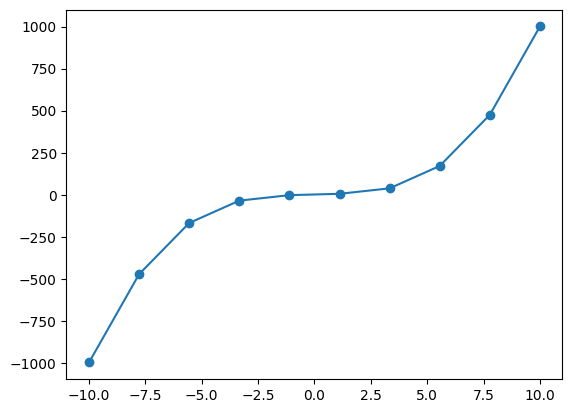

In [ ]:
plt.plot(x, [f_math(xi) for xi in x])     #Recorro el array de 1 en 1, para que
                                          #fmath funcione
plt.scatter(x, [f_math(xi) for xi in x])

However, who wants to do that?

`numpy` is a library that provides more control on vector operations than the one provided by the basic python arrays.

Let's import the library, redefine and re-plot the function.

In [ ]:
import numpy as np

In [ ]:
def f(x):
    return 2 + 3*np.sin(x) + x*x*x

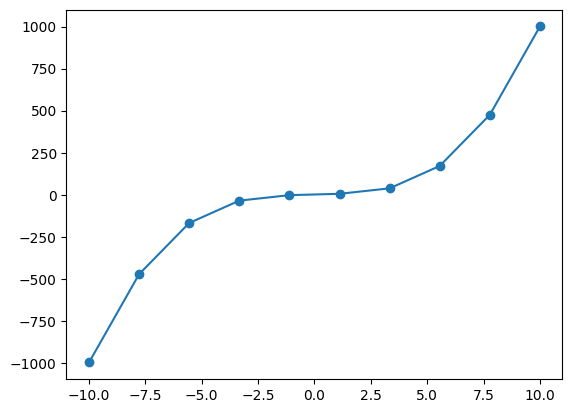

In [ ]:
plt.plot(x, f(x))   #Si ejecutas plt.plot(x, f(x)),
                    #vas a dibujar la gráfica de la función matemática (f(x)
                    #en el intervalo y con la resolución que hayas definido para tu variable x

plt.scatter(x, f(x))  #Si pones plt.scatter(x, f(x)),
                      #vas a dibujar los puntos exactos de la función matemática
                       #(f(x)
                      #pero completamente sueltos, sin ninguna línea que los una.

We will also define our own plotting function, to have points and lines at the same time

In [ ]:
#NOMBRE DE FUNCION : myplot

#Hace PLOT y SCATTER juntas

def myplot(x, y, label=''):      #Funcion que une las 2 funciones de plt anteriores
    plt.plot(x, y, label=label)
    plt.scatter(x, y)

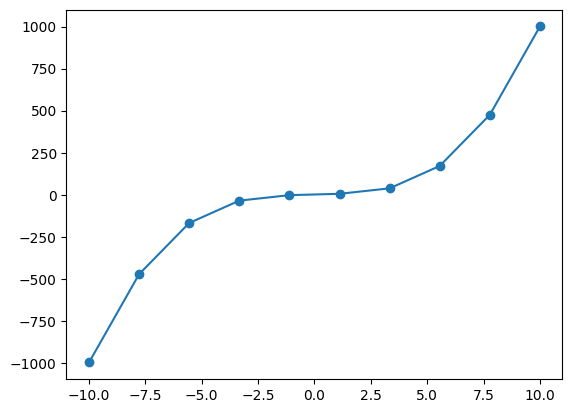

In [ ]:
myplot(x, f(x))     #Como parametro le ingreso x y la funcion para obtener con
                    #plot el grafico de la funcion en una linea
                    #con scatter los puntos dispersos

Now we can compute and plot the analytical derivative of `f`

In [ ]:
def anal_deriv(x):
    return 3*np.cos(x)+ 3*x**2             # Hago la derivada analítica
                                          # (calculada manualmente a mano) de la
#Por eso uso el coseno                     # función original
#El codigo no hace nada, yo hago a mano la derivada

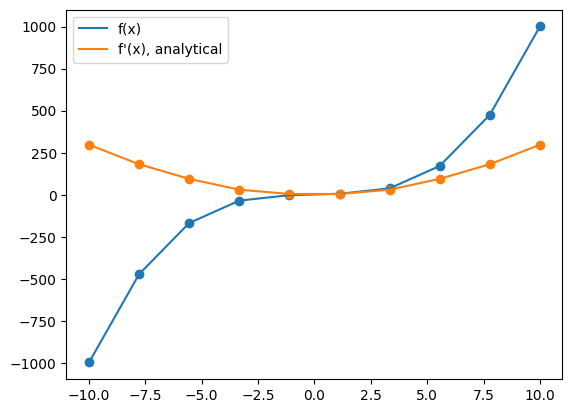

In [ ]:
myplot(x, f(x), label="f(x)")    #calculo el plot y el scatter para la funcion original
                                 #"label" es solo el texto que va a salir en el grafico


#calculo el plot y el scatter de la derivada analitica
myplot(x, anal_deriv(x), label="f'(x), analytical")
plt.legend()  #muestra un recuadro con la leyenda en un gráfico para
              #identificar qué representa cada línea o elemento dibujado

We can plot the function to an arbitrary level of precision (up to machine precision), by evaluating the functions in more points


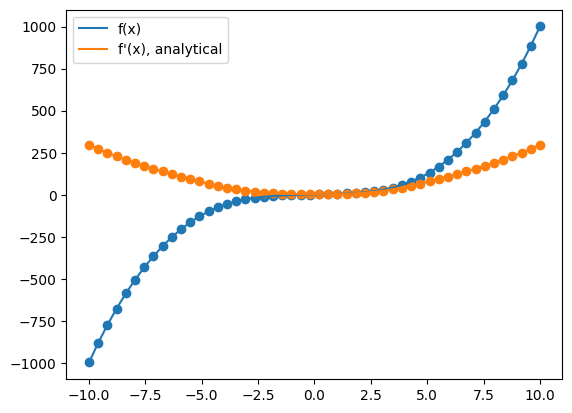

In [ ]:
x = np.linspace(-10,10, 50)   #aumento el numero de puntos a 50 (es más preciso)
#recordar que linspace es un array que tiene elentos de -10, 10

#plot une todos los 50 puntos en linea recta cada uno (creando la funcion azul)
#scatter muestra todos los puntos sin unir

myplot(x, f(x), label="f(x)")
myplot(x, anal_deriv(x), label="f'(x), analytical")
plt.legend()

Let's go back to our 10 points

In [ ]:
x = np.linspace(-10,10, 10)


Symbolic differentiation is based on software that interprets the expression obtaining its symbolic form. Any additional operation, like for instance taking the derivative of the function, is performed by acting on the symbolic expression.

We will use the package `sympy` to translate our function into a symbolic expression, and to then calculate the symbolic derivative

In [ ]:
import sympy       #SEGUNDO TIPO DE DERIVADA (SIMBOLICA)

In [ ]:
symbolic_x = sympy.symbols('x')  #Crea la variable 'x' como un símbolo algebraico abstracto
symbolic_func = f(symbolic_x)    #Crea una funcion simbolica
symbolic_func

sym_y = sympy.lambdify(symbolic_x,symbolic_func)(x)


TypeError: loop of ufunc does not support argument 0 of type Symbol which has no callable sin method

What is happening? `sympy` does not recognize `numpy`-specific expressions, so we will have to revert back to using our basic expression based on the `math`library

In [ ]:
import sympy

symbolic_x = sympy.symbols('x')
symbolic_func = f_math(symbolic_x)
symbolic_func

sym_y = sympy.lambdify(symbolic_x,symbolic_func)(x)


TypeError: Cannot convert expression to float

However, not even that is working: `sympy` seems to be able to access `math` functions, but having represented `x` in symbolic form prevents it to be passed to `math.sin`, which expects a float.

As it often happens, the solution is to use `sympy`'s own definition of `sin`.

In [ ]:
def f_sympy(x):               #Usar sympy.sin en vez de la funcion de la libreria math
    return 2 + 3*sympy.sin(x)+ x**3
x_symb = sympy.symbols('x')   #Creo la variable simbolica X
f_symb = f_sympy(x_symb)      #Creo la funcion usando la variable simbolica
f_symb

x**3 + 3*sin(x) + 2

Note that `sympy` reorders the terms according to its own rules.

We can now let the software calculate the symbolic derivative very easily

In [ ]:
symb_deriv = f_symb.diff(x_symb)      #symb.diff calcula la derivada usando el
                                      #metodo SIMBOLICO
#la derivada simbólica exacta de la expresión utilizando el motor algebraico de SymPy
symb_deriv    #lo muestra por pantalla



3*x**2 + 3*cos(x)

Now let's plot the symbolic derivative.
In order to obtain an array of numbers (which is what `matplotlib` expects), we will evaluate the function on our `x` by converting the symbolic expression into a python `lambda` function

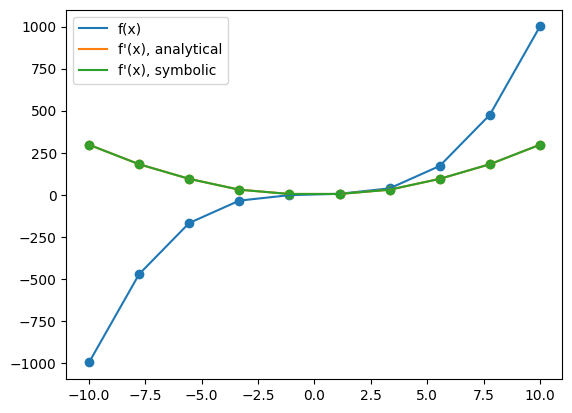

In [ ]:
#Hago plt.plot y scatter de la FUNCION ORIGINAL
myplot(x, f(x), label="f(x)")

#Hago plt.plot y scatter de la DERIVADA ANALITICA
myplot(x, anal_deriv(x), label="f'(x), analytical")

#Hago plt.plot y scatter de la DERIVADA SIMBOLICA
myplot(x, sympy.lambdify(x_symb,symb_deriv)(x), label="f'(x), symbolic")

#Nota: La linea verde y naranja se superponen porque son la misma derivada


#Muestro los labels
plt.legend()

The symbolic derivative always matches with the exact derivative!

This is always true, no matter whether you evaluate it in more points or less points:

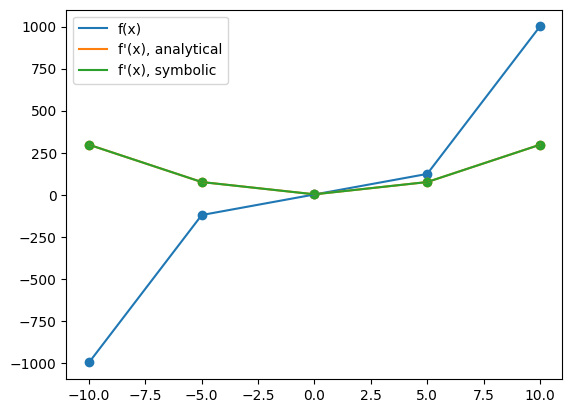

In [ ]:
x_fewpoints = np.linspace(-10,10, 5)   #Creo un array con menos puntos (menos preciso)

#---Lo mismo que lo anterior pero con menos puntos en el array----

#Hago plt.plot y scatter de la FUNCION ORIGINAL
myplot(x_fewpoints, f(x_fewpoints), label="f(x)")

#Hago plt.plot y scatter de la DERUVADA ANALITICA
myplot(x_fewpoints, anal_deriv(x_fewpoints), label="f'(x), analytical")

#Hago plt.plot y scatter de la DERIVADA SIMBOLICA
myplot(x_fewpoints, sympy.lambdify(x_symb,symb_deriv)(x_fewpoints), label="f'(x), symbolic")


plt.legend()

However, symbolic differentiation applied to long or complicated expressions tends to result in huge derivative expressions that are slow to evaluate

In [ ]:
#Creo una funcion "complicada" de derivar

def complicated_f(x):
    #return 2 + sympy.atan(x)*sympy.sin(x)+sympy.cos(x+3)*sympy.log(x)**3
    return 64*x*(1-x)*((1-2*x)**2)*(1-8*x+8*x**2)**2

x_symb = sympy.symbols('x')
f_comp_symb = complicated_f(x_symb)
f_comp_symb    #Imprimo la nueva funcion de manera simbolica


64*x*(1 - 2*x)**2*(1 - x)*(8*x**2 - 8*x + 1)**2

In [ ]:
#Ejecuto el metodo symb.diff
#Para derivar de manera simbolica

comp_symb_deriv = f_comp_symb.diff(x_symb)
comp_symb_deriv

64*x*(1 - 2*x)**2*(1 - x)*(32*x - 16)*(8*x**2 - 8*x + 1) - 64*x*(1 - 2*x)**2*(8*x**2 - 8*x + 1)**2 + 64*x*(1 - x)*(8*x - 4)*(8*x**2 - 8*x + 1)**2 + 64*(1 - 2*x)**2*(1 - x)*(8*x**2 - 8*x + 1)**2

Let's now calculate numerical derivatives, using the finite differences method.

Exercise: you could also modify the formula to use the central finite differences, that provides a somehow better precision.

In [ ]:
#TERCER 3 METODO DE DERIVACION  - Metodo NUMERICO

#Basicamente es la definicion de derivacion por limite

#Usando la definicion de limite con un valor que se acerca a epsilon

def num_deriv(x, epsilon):
    return (f(x+epsilon)-f(x))/epsilon

We can now compare the derivatives we obtained. We will not plot the function `f(x)`, so that we can zoom better on the behaviour of the derivatives

<>:15: SyntaxWarning: invalid escape sequence '\e'
<>:20: SyntaxWarning: invalid escape sequence '\e'
<>:15: SyntaxWarning: invalid escape sequence '\e'
<>:20: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1796/3828252475.py:15: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipykernel_1796/3828252475.py:20: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")


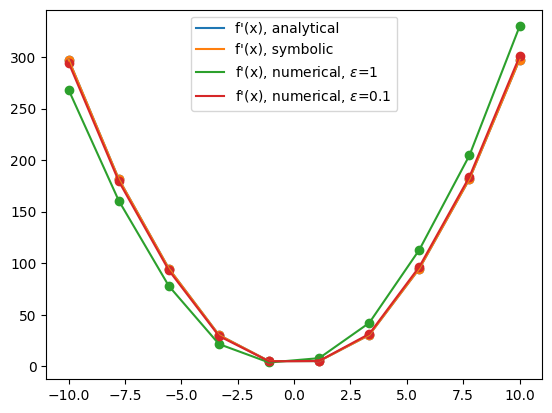

In [ ]:
#myplot(x, f(x), label="f(x)")   YA no mostramos la funcion

#Seguimos usando "x" con 10 puntos

#Plot y scatter de DERIVADA ANALITICA
myplot(x, anal_deriv(x), label="f'(x), analytical")


#Plot y scatter de DERIVADA SIMBOLICA
myplot(x, sympy.lambdify(x_symb,symb_deriv)(x), label="f'(x), symbolic")


#Plot y scatter de DERIVADA NUMERICA POR LIMITE EPSILON
epsilon=1   #Hago que epsilon seea 1
myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")


#Plot y scatter de DERIVADA NUMERICA POR LIMITE EPSILON
epsilon=0.1  #Hago que epsilon sea 0.1 , resultado de limite mas preciso
myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")

#Muestro los labels de cada grafico
plt.legend()


#Se observa que la funcion verde la cual fue calculada de forma numerica
#Con un EPSILON 1, es la menos precisa de las 4

Numerical derivatives differ significatively from the exact derivatives when the step $\epsilon$ is large.
The smaller the step, the better is the numerical approximation.

However, if $\epsilon$ becomes too small...

<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:16: SyntaxWarning: invalid escape sequence '\e'
<>:21: SyntaxWarning: invalid escape sequence '\e'
<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:16: SyntaxWarning: invalid escape sequence '\e'
<>:21: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1796/1697119847.py:11: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipykernel_1796/1697119847.py:16: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipykernel_1796/1697119847.py:21: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")


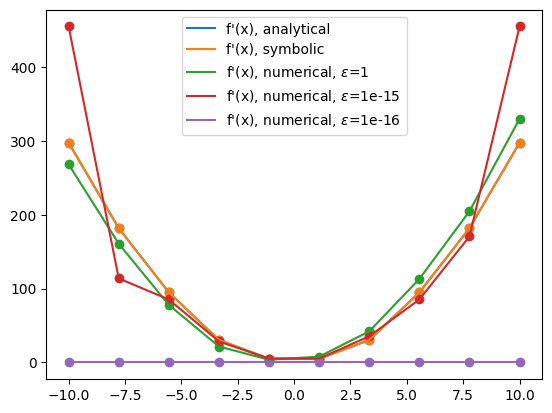

In [ ]:
#myplot(x, f(x), label="f(x)")


#Plot y scatter de DERIVADA SIMBOLICA
myplot(x, anal_deriv(x), label="f'(x), analytical")
myplot(x, sympy.lambdify(x_symb,symb_deriv)(x), label="f'(x), symbolic")


#Plot y scatter de DERIVADA NUMERICA POR LIMITE EPSILON  1
epsilon=1
myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")


#Plot y scatter de DERIVADA NUMERICA POR LIMITE EPSILON 1e-15 (numero pequeño)
epsilon=1e-15
myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")


#Plot y scatter de DERIVADA NUMERICA POR LIMITE EPSILON 1e-16 (numero más pequeño)
epsilon=1e-16
myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")

#Mostrar los labels de todos los graficos
plt.legend()


#Vemos quue con EPSILON muy pequeños, el METODO NUMERICO DEL LIMITE falla
#Da resultados cada vez menos precisos

### Comparación con la Derivada Analítica (Error Relativo)

En esta celda se calcula y grafica el **error relativo** de la derivada simbólica y de la derivada numérica (evaluada con distintos valores de $\epsilon$) respecto a la derivada analítica exacta[cite: 144].

#### Fórmula empleada
$$\text{Error Relativo} = \frac{f'(x)_{\text{método}} - f'(x)_{\text{analítico}}}{f'(x)_{\text{analítico}}}$$

---

#### Explicación del gráfico obtenido

* **Derivada Simbólica (`symbolic` - Azul):**
  Línea constante en $0.0$[cite: 145]. Al ser un cálculo algebraico exacto, no presenta error respecto a la derivada analítica[cite: 142, 144].

* **$\epsilon = 1$ (Naranja) y $\epsilon = 0.1$ (Verde) — Error de Truncamiento:**
  Con pasos grandes la aproximación por secante es imprecisa[cite: 143, 145]. Con $\epsilon = 1$ el error es alto, pero al reducirlo a $\epsilon = 0.1$ disminuye sustancialmente acercándose a cero[cite: 144, 145].

* **$\epsilon = 10^{-15}$ (Rojo) — Cancelación Catastrófica:**
  Al acercarse al límite de precisión de $64$ bits (`float64`), la resta $f(x+\epsilon) - f(x)$ pierde dígitos significativos, generando inestabilidad y ruido numérico en la gráfica[cite: 143, 144, 145].

* **$\epsilon = 10^{-16}$ (Morado en $-1.0$) — Límite de Precisión:**
  El valor $10^{-16}$ cae por debajo de la precisión de máquina al sumarse a $x$[cite: 144, 145]. El ordenador interpreta $x + 10^{-16} = x$, dando $f(x+\epsilon) - f(x) = 0$[cite: 143, 144]. Al valer $0$ la derivada numérica, la fórmula del error relativo resulta en:

  $$\frac{0 - f'(x)_{\text{analítico}}}{f'(x)_{\text{analítico}}} = -1.0$$

  Por eso la línea morada queda recta en **$-1.0$**[cite: 144, 145].

<>:6: SyntaxWarning: invalid escape sequence '\e'
<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:15: SyntaxWarning: invalid escape sequence '\e'
<>:19: SyntaxWarning: invalid escape sequence '\e'
<>:6: SyntaxWarning: invalid escape sequence '\e'
<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:15: SyntaxWarning: invalid escape sequence '\e'
<>:19: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1796/727642687.py:6: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipykernel_1796/727642687.py:11: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipykernel_1796/727642687.py:15: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipyke

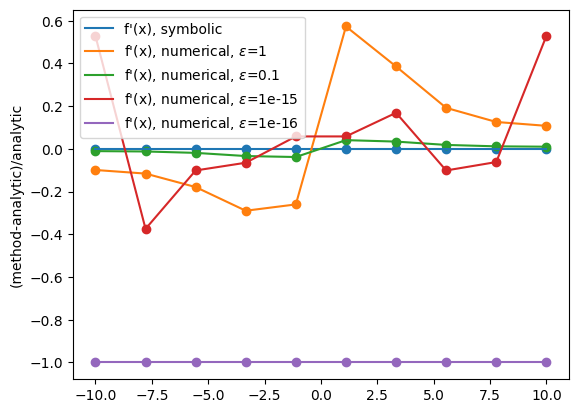

In [ ]:
#Plot y scatter de DERIVADA SIMBOLICA
myplot(x, (sympy.lambdify(x_symb,symb_deriv)(x)-anal_deriv(x))/anal_deriv(x), label="f'(x), symbolic")

#Plot y scatter de DERIVADA NUMERICA POR LIMITE EPSILON  1
epsilon=1
myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")


#Plot y scatter de DERIVADA NUMERICA POR LIMITE EPSILON  0.1
epsilon=0.1
myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")

#Plot y scatter de DERIVADA NUMERICA POR LIMITE EPSILON  1e-15
epsilon=1e-15
myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")

#Plot y scatter de DERIVADA NUMERICA POR LIMITE EPSILON  1e-16
epsilon=1e-16
myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")


#Muesto los labels de cada funcion
plt.legend()


plt.ylabel("(method-analytic)/analytic")   #Label en el eje Y
plt.legend()   #Mostrar las leyendas


#Ver grafico para entender mejor

# Diferenciación Automática con Números Duales

## 1. ¿Qué es un Número Dual?
Un **número dual** es un objeto matemático similar a los números complejos, de la forma:

$$z = a + b\epsilon$$

* **$a$ (Parte Primal):** Almacena el **valor de la función** $f(x)$[cite: 146].
* **$b$ (Parte Tangente):** Almacena el **valor de la derivada** $f'(x)$[cite: 146].
* **Propiedad Fundamental:** El parámetro $\epsilon$ cumple que $\epsilon \neq 0$, pero **$\epsilon^2 = 0$**[cite: 146].

---

## 2. Recordatorio: Serie de Taylor y Exactitud Numérica

La expansión en **Serie de Taylor** para evaluar una función en un punto perturbado $x + \epsilon$ es:

$$f(x + \epsilon) = f(x) + f'(x)\epsilon + \frac{f''(x)}{2!}\epsilon^2 + \frac{f'''(x)}{3!}\epsilon^3 + \dots$$

Al aplicar la regla de los números duales ($\epsilon^2 = 0$), todos los términos de segundo orden en adelante ($\epsilon^2, \epsilon^3, \dots$) **se cancelan estrictamente**[cite: 146]:

$$f(x + \epsilon) = f(x) + f'(x)\epsilon$$

> **Resultado:** A diferencia del método numérico (que trunca la serie y genera errores), la diferenciación automática con números duales calcula el valor de la función y su **derivada exacta** en una sola pasada[cite: 146].

---

## 3. Estrategia en Código: Sobrecarga de Operadores (*Operator Overloading*)

ES EL OVERWRITE DE JAVA. Metodos con el mismo nombre (polimorfismo) pero distinta funcionalidad.  OVER-WRITE

Para adaptar nuestro código estándar a esta matemática:
1. Definimos una clase `DualNumber` en Python que guarda `primal` ($a$) y `tangent` ($b$)[cite: 146, 147].
2. Sobrecargamos (OVERWRITE) los operadores básicos (`+`, `*`, etc.) y funciones como `sin()` dentro de la clase[cite: 146, 147].
3. Al realizar operaciones, la clase aplica automáticamente las reglas de derivación (suma, regla del producto, regla de la cadena) actualizando ambas partes simultáneamente[cite: 146].

All that remains is now to examine automatic differentiation and to see how it compares with the methods above!

We could jump directly into using one of the awesome autodiff packages that are on the market, but what would be the fun in that?

## Let's try to implement automatic differentiaton by ourselves!

### Dual numbers

We have seen that dual numbers, i.e. numbers that can be written as $a+b\epsilon$, where $\epsilon^2=0$, can be used to represent a small perturbation $P(x+\epsilon)$ of a polynomial function $P(x)$. Developing the expression, we soon obtain the important result

$P(x+\epsilon) = \ldots = P(x) + \epsilon \frac{dP(x)}{dx}$.

Generalizing, we can use dual numbers to rewrite a function of a real number as a function that takes a dual number as an input, and holds the value of the function in the principal part of the dual number, and its derivative in the dual part of the dual number:

$f(a + b\epsilon) = f(a) +\epsilon f'(a)$

### Operator overloading

To use this property of dual numbers, we need a way of converting our code in such a way that each function that normally would take a `float` as an input now takes a dual number.

In python (or in C++, or in pretty much any object-oriented language) this is very easy: we can define a class that uses dual numbers arithmetic, and then we simply feed a function a dual number instead of a float.

We only have to take good care to reimplement any operator of the type class (multiplication, addition, subtraction, etc) that is present in the functions we want to feed this dual numbers to! We will also have to reimplement any accessory function like `sin(x)`, and rewrite our function to use our new implementation.

Exercise: can you figure out what to put into the missing part of the class below?
Attention: is the expression for

In [ ]:
class DualNumber:
  #__init__ es el CONSTRUCTOR
  #Recibe self es "this" , primal a y tangent b como PARAMETROS

        def __init__(self, primal, tangent=0):
                self.primal=primal     #this.primal=primal
                self.tangent=tangent   #this.tangent= tangent

        #DEFINO METODOS (hago overwrite de SUMA, RMUL, MUL)

        #Sumo 2 numeros DUALES, debo sumar las partes primales, y la parte tangente de cada uno
        #Devuelvo un nuevo objeto con los nuevos valores
        #"other" es otro numero dual

        def __add__(self, other):
          #Creo el nuevo OBJETO
                return DualNumber(
                      self.primal+other.primal ,self.tangent+other.tangent)


        #Multiplico "self" que es un numero dual
        #por "a" un numero REAL

        #"rmul" reverse multiplication
        #multiplico el valor "a" por la parte primal y la tangente
        #Creo un nuevo numero DUAL,con eso en mente
        def __rmul__(self, a):
                return DualNumber(
                    self.primal*a, self.tangent*a )


        #Multiplico 2 numeros duales
        #self * other
        #New Primal = Multiplico la parte primal de cada uno
        #New Tangent = Multiplico parte primal 1*parte tangente 2 +
                        #parte primal 2*parte tangente 1

        #Recordar que multiplicar 2 partes tangente dan 0
        #porque epsilon*epsilon=0

        #Creo un nuevo OBJETO de clase DualNumber
        def __mul__(self, other):
                return DualNumber(
                    self.primal*other.primal , self.primal*other.tangent +
                                                other.primal*self.tangent )


#Creo una funcion SENO, que recibe val
#"val" es un numero dual con parte PRIMAL y TANGENTE

#El seno de un numero dual se calcula como:
#   sin(primal) + tangente * coseno(primal)
#Y eso es un numero numero DUAL en un objeto

#uso la libreria MATH

def dualsin(val):
        return DualNumber(math.sin(val.primal) ,
                          val.tangent * math.cos(val.primal))


#Voy a definir ahora mi FUNCION ORIGINAL pero con numeros DUALES
#Debo usar los metodos para numeros duales que he ido creando
#"xd" es un numero DUAL

#como use __mul__ son metodos que ya viene por defecto en la clase

#Python detecta que "xd" es un numero DUAL y aplica la sobreescritura de metodos
#para nummeros duales usando los simbolos de suempre > "+", "*"

#"dualsin" es un metodo no OVERWRITE, entonces debo llamarlo

def f_withduals(xd):
        #return 2*xd + 3*sin(xd) + xd*xd*xd  - Eso es lo que deberia hacer
        return 2 * xd + 3 * dualsin(xd) + xd *xd *xd  #solo incorporo dualsin


def anal_deriv(x): # We redefine the previous analytic derivative, because now we have 2x as first temr
    return 2+3*np.cos(x)+ 3*x**2

xd = DualNumber(1.,1.)      #es un Dual number con parte primal 1 y tangente 1
z = f_withduals(xd)

print("z =", z.primal)
print("dc/dx =", z.tangent)

z = 5.524412954423689
dc/dx = 6.620906917604419


### Fundamentos Matemáticos de la Clase `DualNumber`

Un número dual se define como $z = a + b\epsilon$, donde $a$ representa la evaluación de la función (parte **primal**), $b$ representa el valor de la derivada (parte **tangente**) y $\epsilon$ cumple la condición fundamental **$\epsilon^2 = 0$**[cite: 146].

---

#### 1. Suma de Números Duales (`__add__`)
Al sumar dos números duales $u = a + b\epsilon$ y $v = c + d\epsilon$:

$$(a + b\epsilon) + (c + d\epsilon) = (a + c) + (b + d)\epsilon$$

* **Parte Primal:** Suma directa de los valores $\rightarrow a + c$.
* **Parte Tangente:** Aplica la **regla de la suma** de derivadas: $(f + g)' = f' + g'$.

---

#### 2. Multiplicación por un Escalar (`__rmul__`)
Al multiplicar una constante real $k$ por un número dual $u = a + b\epsilon$:

$$k \cdot (a + b\epsilon) = (k \cdot a) + (k \cdot b)\epsilon$$

* **Parte Primal:** Escalado del valor original $\rightarrow k \cdot a$.
* **Parte Tangente:** Aplica la regla de la **constante por una función**: $(k \cdot f)' = k \cdot f'$.

---

#### 3. Multiplicación de dos Números Duales (`__mul__`)
Al multiplicar dos números duales $u = a + b\epsilon$ y $v = c + d\epsilon$:

$$(a + b\epsilon) \cdot (c + d\epsilon) = a \cdot c + a \cdot d\epsilon + b \cdot c\epsilon + b \cdot d\epsilon^2$$

Como por definición **$\epsilon^2 = 0$**, el término cuadrático se anula automáticamente[cite: 146]:

$$(a + b\epsilon) \cdot (c + d\epsilon) = (a \cdot c) + (a \cdot d + b \cdot c)\epsilon$$

* **Parte Primal:** Producto de los valores primales $\rightarrow a \cdot c$.
* **Parte Tangente:** Reproduce de forma exacta la **regla del producto de Leibniz**: $(f \cdot g)' = f \cdot g' + f' \cdot g$.

---

#### 4. Evaluación de Funciones / Seno (`dualsin`)
Para evaluar cualquier función diferenciable $f$ en un número dual $u = a + b\epsilon$, usamos la expansión en Serie de Taylor considerando $\epsilon^2 = 0$[cite: 146]:

$$f(a + b\epsilon) = f(a) + f'(a) \cdot b\epsilon$$

Aplicado a la función seno ($f(x) = \sin(x)$ con $f'(x) = \cos(x)$):

$$\sin(a + b\epsilon) = \sin(a) + \cos(a) \cdot b\epsilon$$

* **Parte Primal:** Evaluación del seno sobre la parte primal $\rightarrow \sin(a)$.
* **Parte Tangente:** Aplica la **regla de la cadena** multiplicando la derivada del seno ($\cos(a)$) por la derivada interna ($b$) $\rightarrow b \cdot \cos(a)$.

Try to do it yourself!!!
.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.



...but you can also simply use the full implementation below.

Note two things:
- we had to replace the floats `2`and `3` in the function with their dual counterpart. This is necessary.
- we modified the return value of the function to support array inputs and outputs. This is not necessary, we did it just to be able to then plot the autodiff derivative in the same way as we plot the other types of derivatives.

In [ ]:
class DualNumber:
        def __init__(self, primal, tangent=0):
                self.primal=primal
                self.tangent=tangent
        def __add__(self, other):
                return DualNumber(
                        self.primal+other.primal, self.tangent+other.tangent)
        def __rmul__(self, a):
                return DualNumber(
                        self.primal*a, self.tangent*a)
        def __mul__(self, other):
                return DualNumber(
                        self.primal*other.primal, self.primal*other.tangent+ self.tangent*other.primal)
def sin(val):
        return DualNumber(
                math.sin(val.primal),
                math.cos(val.primal)*val.tangent)



In [ ]:
from typing import List

#Es otra "implementacion" de hacer f_withduals
#La que hicimos arriba igual funciona, pero esta usa listas y arrays
#Mas que nada para que plt.plot y plt.scatter funcionen bien

#overWRITE de f_withduals
def f_withduals(xs):
    if isinstance(xs, List):
      # return 2 * xd + 3 * dualsin(xd) + xd *xd *xd
        return np.array( [ DualNumber(2,0)*xi + DualNumber(3, 0)*sin(xi)+ xi*xi*xi for xi in xs] )
    else:
        return DualNumber(2,0)*xs + DualNumber(3, 0)*sin(xs) + xs*xs*xs

print( type(np.array([1])))
xd = DualNumber(1.,1.)  #Parte Primal = 1 y Tangente = 1
z = f_withduals(xd)

print("z =", z.primal, ", to be compared with", f(1))
print("df(x)/dx =", z.tangent, ", to be compared with", anal_deriv(1))


<class 'numpy.ndarray'>
z = 5.524412954423689 , to be compared with 5.524412954423689
df(x)/dx = 6.620906917604419 , to be compared with 6.620906917604419


The autodiff derivative matches perfectly the analytical derivative.  ***SON IGUALITAS PUES la derivada analitica = derivada AUTODIFF***

### Automatic differentiation provides exact numerical derivatives.

Let's now see what happens if we set the derivative of the input to zero:

In [ ]:
xd = DualNumber(1.,0)
z = f_withduals(xd)

print("z =", z.primal, ", to be compared with", f(1))
print("df(x)/dx =", z.tangent, ", to be compared with", anal_deriv(1))


#Siempre el numero dual, debe tener como parte TANGENTE=1
#Para que la derivada funcione bien

z = 5.524412954423689 , to be compared with 5.524412954423689
df(x)/dx = 0.0 , to be compared with 6.620906917604419


In automatic differentiation, for derivatives to be propagated correctly we must provide an input derivative of $1$, corresponding to the first differentiation in the chain rule, i.e. the derivative of the input with respect to itself).

> ### 💡 ¿Por qué la parte tangente debe inicializarse en `1`?
>
> * **`tangent = 1` ($\frac{dx}{dx} = 1$):** Representa la derivada de la variable $x$ respecto a sí misma[cite: 152]. Funciona como la "semilla" inicial necesaria para activar la propagación de derivadas mediante la regla de la cadena[cite: 152].
> * **`tangent = 0` ($\frac{dx}{dx} = 0$):** Equivale a tratar a la variable $x$ como una constante[cite: 152]. Al no haber variación inicial, la regla de la cadena multiplica todo por cero y la derivada resultante devuelve `0.0`[cite: 152].
>
> **En resumen:** Para calcular la derivada $f'(x)$ de una función respecto a su entrada $x$, el número dual inicial **siempre debe crearse con `tangent = 1`**[cite: 152].

We are now ready to compare our autodiff derivative with the other derivatives we used above.

<>:18: SyntaxWarning: invalid escape sequence '\e'
<>:24: SyntaxWarning: invalid escape sequence '\e'
<>:30: SyntaxWarning: invalid escape sequence '\e'
<>:18: SyntaxWarning: invalid escape sequence '\e'
<>:24: SyntaxWarning: invalid escape sequence '\e'
<>:30: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1796/3875257573.py:18: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipykernel_1796/3875257573.py:24: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipykernel_1796/3875257573.py:30: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")


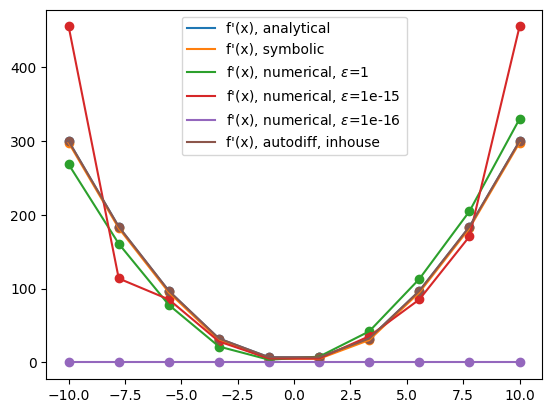

In [ ]:
x_dual = [ DualNumber(xi, 1.) for xi in x ]       #Hago DUAL NUMBERS con

#Parte PRIMAL los valores de cada punto , y tangente=1, derivar con respecto a X

#myplot(x, f(x), label="f(x)")  FUNCION ORIGINAL


#Plot y Scatter para DERIVADA ANALITICA
myplot(x, anal_deriv(x), label="f'(x), analytical")


#Plot y Scatter para DERIVADA SIMBOLICA
myplot(x, sympy.lambdify(x_symb,symb_deriv)(x), label="f'(x), symbolic")


#Plot y Scatter para DERIVADA NUMERICA DEL LIMITE CON EPSILON 1
epsilon=1
myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")



#Plot y Scatter para DERIVADA NUMERICA DEL LIMITE CON EPSILON 1e-15
epsilon=1e-15
myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")



#Plot y Scatter para DERIVADA NUMERICA DEL LIMITE CON EPSILON 1e-16
epsilon=1e-16
myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")



#Plot y Scatter para DERIVADA CON AUTODIFF
myplot(x, [xi.tangent for xi in f_withduals(x_dual)], label="f'(x), autodiff, inhouse")

#Imprimo los labels de todas las funciones
plt.legend()

COMPROBACION DE LO LEJOS QUE ESTAN CON RESPECTO A LA DERIVADA ANALITICA (LA CORRECTA)

<>:6: SyntaxWarning: invalid escape sequence '\e'
<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:16: SyntaxWarning: invalid escape sequence '\e'
<>:21: SyntaxWarning: invalid escape sequence '\e'
<>:6: SyntaxWarning: invalid escape sequence '\e'
<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:16: SyntaxWarning: invalid escape sequence '\e'
<>:21: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1796/3367866160.py:6: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipykernel_1796/3367866160.py:11: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ipykernel_1796/3367866160.py:16: SyntaxWarning: invalid escape sequence '\e'
  myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")
/tmp/ip

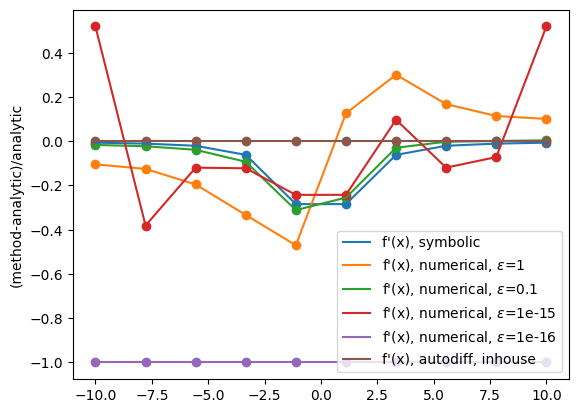

In [ ]:

#DERIVADA SIMBOLICA
myplot(x, (sympy.lambdify(x_symb,symb_deriv)(x)-anal_deriv(x))/anal_deriv(x), label="f'(x), symbolic")

#DERIVADA NUMERICA EPSILON 1
epsilon=1
myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")


#DERIVADA NUMERICA EPSILON 0.1
epsilon=0.1
myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")


#DERIVADA NUMERICA EPSILON 1e-15
epsilon=1e-15
myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")


#DERIVADA NUMERICA EPSILON 1e-16
epsilon=1e-16
myplot(x, (num_deriv(x, epsilon)-anal_deriv(x))/anal_deriv(x), label=f"f'(x), numerical, $\epsilon$={epsilon}")


#DERIVADA con AUTODIFF
myplot(x, ([xi.tangent for xi in f_withduals(x_dual)]-anal_deriv(x))/anal_deriv(x), label="f'(x), autodiff, inhouse")


plt.legend()


plt.ylabel("(method-analytic)/analytic")
plt.legend()


#Si el resultado es 0
#Es decir una recta horizonal en el punto 0
#Quiere decir que la derivada es exactamente igual a la derivada analitica (la correcta)

OK, so automatic differentiation is cool, it works, and it is fast!!!

It is now time to take a look at automatic differentiation in one of the most popular autodiff frameworks, `torch`.

`Torch` is a library for tensor calculus developed mainly for machine learning purposes. You may recall from the lecture that most of modern machine learning based on perceptrons consists essentially in products of arbitrarily dimensioned matrices, i.e. **tensors**

In [ ]:
import torch

In [ ]:
xt = torch.tensor(x, requires_grad=False)

f_torch =  f_torch = 2 + 3*torch.sin(xt)+ xt**3

With torch, we can also examine first-hand the concept of Wengert list (computational graph) that we have discussed during the lecture!

The package `torchviz` provides an easy way of printing the computational graph of any expression. We need to install it with `pip` because it is not included in the conda channels we used

# Introducción a PyTorch y Diferenciación Automática

## 1. ¿Qué es un Tensor?
Un **tensor** es la estructura de datos fundamental en PyTorch. Es la generalización matemática de vectores y matrices a $N$ dimensiones:
* **Dimensión 0:** Escalar (un solo número).
* **Dimensión 1:** Vector (1D).
* **Dimensión 2:** Matriz (2D).
* **Dimensión $N$:** Tensor ($N$-dimensional).

> **Puntos clave:** Son equivalentes a los arrays de NumPy (`np.array`), pero pueden ejecutarse en **GPU** y rastrean operaciones para calcular derivadas automáticas.

---

## 2. El Parámetro Clave: `requires_grad`

Al crear un tensor con `torch.tensor(x, requires_grad=...)`:

* **`requires_grad=True`:** Le indica a PyTorch que active el rastreo de derivadas para esta variable (equivale a fijar `tangent = 1` en nuestro objeto `DualNumber`).
* **`requires_grad=False`:** Trata al tensor como un valor constante o dato de entrada fijo, ignorando el cálculo de su derivada para ahorrar memoria.

---

## 3. Grafo Computacional (*Wengert List*)

A diferencia de la diferenciación hacia adelante (*forward mode*) con Números Duales, PyTorch utiliza **Diferenciación Automática en Modo Inverso (*Reverse-mode Autodiff / Backpropagation*)**:

1. **Pasada Hacia Adelante (*Forward Pass*):** Evalúa la función matemática y construye en memoria un mapa de operaciones llamado **Grafo Computacional** o **Lista de Wengert**.
2. **Pasada Hacia Atrás (*Backward Pass*):** Recorre el grafo en sentido inverso aplicando la regla de la cadena para obtener los gradientes de todas las variables de forma masiva y eficiente.

---

## 4. Visualización del Grafo (`torchviz`)

La librería `torchviz` (método `make_dot`) permite representar gráficamente el diagrama de flujo de operaciones creadas por PyTorch, mostrando cómo se conectan los tensores y las funciones intermedias.

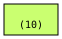

In [ ]:
!pip install torchviz
from torchviz import make_dot
make_dot(xt)


The tensor `xt` is indeed a simple tensor.

What about the function?

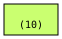

In [ ]:
make_dot(f_torch)

There is something going on. The function should not have the same computational graph as its input tensor.

Let's forget this for a moment, and try to compute the derivatives: in `torch`, the directive that tells the package to propagate derivatives via automatic differentiation is `backward`.

In [ ]:
f_torch.backward(torch.ones_like(f_torch))
print(xt.grad)


#Falla porque al inicio defini requieres_grad como FALSE
#xt = torch.tensor(x, requires_grad=False)

#Eso hace que no pueda hacer REVERSE AUTO DIFFERENCIATION / BACKPROPAGATION
#Debo ponerle TRUE


RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

Weird! Why can't the software calculate derivatives? Well, it seems that `xt` "does not require grad and does not have a grad_fn".

That's because when we defined it we havent requested `pytorch` to keep track of gradients for this tensor!

`Torch` will track only gradients of objects we explicitly require the gradients of, to avoid spending memory and computation time unnecessarily tracking gradients for objects we may not need to differentiate through.

This is what in the lecture we called the `define-and-run` method for building dynamical graphs (as opposed by the `define-and-run` paradigma used e.g. by `tensorflow` to build static graphs).

Let's require `torch` to track gradients for `xt`:

In [ ]:
#Ahora si pongo requieres_grad= TRUE   para que PYTORCH calcule el gradiente
#Hablando en cristiano, que lleve registro de todas las derivadas para poder
#Hacer BackPropagation

xt = torch.tensor(x, requires_grad=True)
f_torch = 2 * xt + 3 * torch.sin(xt) + xt**3   #Faltaba poner 2*xt ERROR DE BASE

In [ ]:
f_torch.backward(torch.ones_like(f_torch))
print(xt.grad)

#Recuerdas que al inicio definimos 10 puntos para graficar la funcion?
#Con backpropagation guardamos el calculo de todas esas 10 derivadas de cada uno
#de esos puntos en el ATRIBUTO grad

#xt.grad, me imprime lo guardado en ese ATRIBUTO

#Imprimo todas las 10 derivadas en cada punto

tensor([299.4828, 183.7099,  96.8329,  32.3883,   7.0347,   7.0347,  32.3883,
         96.8329, 183.7099, 299.4828], dtype=torch.float64)


# Cálculo de Gradientes en PyTorch mediante Backpropagation

## 1. Activar el Grafo Computacional (`requires_grad=True`)
Al declarar `xt = torch.tensor(x, requires_grad=True)`, se le indica a PyTorch que comience a registrar en memoria todas las operaciones matemáticas sobre `xt`[cite: 13].

## 2. Pasada Hacia Adelante (*Forward Pass*)
Al calcular `f_torch = 2 + 3*torch.sin(xt) + xt**3`, PyTorch evalúa el resultado y construye internamente el diagrama de flujo de las operaciones ejecutadas[cite: 13].

## 3. Pasada Hacia Atrás (`f_torch.backward(...)`)
Inicia el algoritmo de **Backpropagation** recorriendo el grafo en sentido inverso con la regla de la cadena[cite: 13]:
* **`torch.ones_like(f_torch)`:** Como `f_torch` es un vector y no un único escalar, se suministra un vector de unos (`1.0`) que actúa como la "semilla" inicial para activar la derivada en cada posición del vector[cite: 13].

## 4. Obtención del Gradiente (`xt.grad`)
El resultado de la derivada exacta se almacena automáticamente dentro de la propiedad **`.grad`** del tensor de entrada (`xt.grad`)[cite: 13].

Now gradients got calculated!

Let's take a look again at the computational graphs:

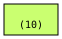

In [ ]:
make_dot(xt)    #Son 10 puntos, por eso sale 10

But now, when we plot the computational graph of `f_torch`...

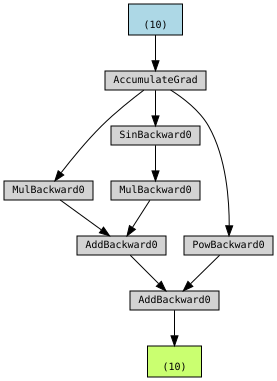

In [ ]:
make_dot(f_torch)    #Ahora hago el grafico computacional para la funcion que
                    #hizo BACKPROPAGATION

Now that we have told torch that we will need to differentiate through `xt`, torch will enable the computational graph calculation for any function that makes use of `xt`.

This is the Wengert list of the function, a Directed Acyclyc Graph of atomic operations.

Note that the names of the functions highlight the fact that each of them (`Add`, `Pow`, etc) is actually present in its "let's track gradients" version (`AddBackward`, `PowBackward`, etc)

# Interpretación del Grafo Computacional (`make_dot`)

El gráfico generado por `torchviz` muestra el **Grafo Aclíclico Dirigido (DAG)** de operaciones inversas que PyTorch utiliza para la propagación hacia atrás (*Backpropagation*)[cite: 10]:

* **Caja verde `(10)` (Nodo de salida):** Representa `f_torch`. Aquí inicia la propagación de gradientes al llamar `.backward()`[cite: 10].
* **Nodos `...Backward`:** Cada operación matemática utilizada en la función tiene asignada su función de derivada inversa (`SinBackward0` para $\sin$, `PowBackward0` para potencias, `AddBackward0` para sumas, etc.)[cite: 10].
* **`AccumulateGrad`:** Consolida los gradientes que provienen de las distintas ramas del grafo aplicando la regla de la suma de derivadas[cite: 10].
* **Caja azul `(10)` (Nodo de entrada):** Representa el tensor de entrada `xt`, donde se almacena el gradiente final acumulado dentro de `xt.grad`[cite: 10].

We are now ready to compare the `torch` autodiff with our inhouse autodiff!

In order for the plot to not be too crowded, let's just compare the two autodiff implementations with each other and with the analytical solution.

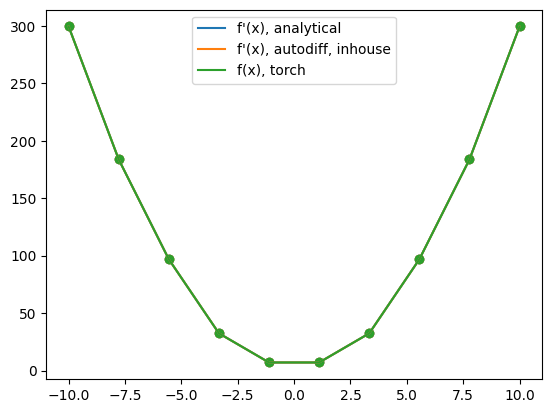

In [ ]:
x_dual = [ DualNumber(xi, 1.) for xi in x ]

#myplot(x, f(x), label="f(x)")    --GRAFICAR LA FUNCION ORIGINAL

#Plot y Scatter para DERIVADA ANALITICA
myplot(x, anal_deriv(x), label="f'(x), analytical")

#----LOS OTROS METODOS DE DERIVACION--------
#myplot(x, sympy.lambdify(x_symb,symb_deriv)(x), label="f'(x), symbolic")
#epsilon=1
#myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")
#epsilon=1e-15
#myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")
#epsilon=1e-16
#myplot(x, num_deriv(x, epsilon), label=f"f'(x), numerical, $\epsilon$={epsilon}")

#Plot y Scatter para IMPLEMENTACION PROPIA DE AUTODIFF (inhouse)
myplot(x, [xi.tangent for xi in f_withduals(x_dual)], label="f'(x), autodiff, inhouse")

#Plot y Scatter para AUTODIFF con PYTORCH
myplot(xt.detach().numpy(), xt.grad.detach().numpy(), label="f(x), torch")

#Muestro la leyenda de ambas derivaas
plt.legend()


#Se ve que los 3 metodos son basicamente IDENTICOS

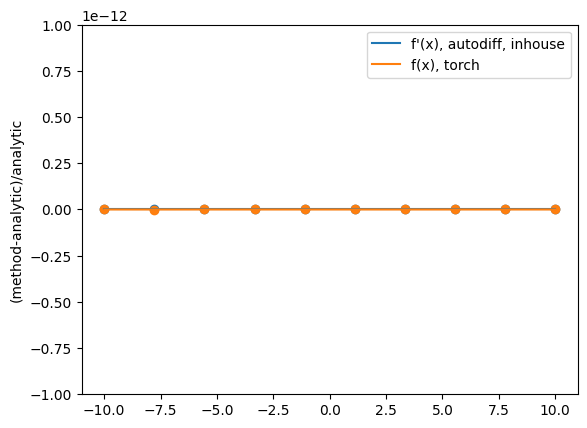

In [ ]:
#DIFERENCIA DE AMBOS METODOS DE DERIVACION CON DERIVADA ANALITICA

#DERIVADA AUTODIFF IMPLEMENTACION PROPIA
myplot(x, ([xi.tangent for xi in f_withduals(x_dual)]-anal_deriv(x))/anal_deriv(x), label="f'(x), autodiff, inhouse")


#DERIVADA AUTODIFF con PYtorch
myplot(xt.detach().numpy(), (xt.grad.detach().numpy()-anal_deriv(x))/anal_deriv(x), label="f(x), torch")


# --- SOLUCIÓN: Definir límites manuales para ignorar el ruido de punto flotante ---
plt.ylim(-1e-12, 1e-12)    #Pongo esto para que el grafica no salgan PICOs por calcular numero muy pequeños

plt.legend()



plt.ylabel("(method-analytic)/analytic")
plt.legend()


#Sale una linea HORIZONTAL en 0. Significando que ambos metodos son iguales
#A la derivada ANALITICA

Wow!!!

Our autodiff implementation is as good as any other one, for these simple examples!

Autodiff is really simple: packages like `torch` just add a lot of bells and whistles:
- almost any function implemented in a way that supports autodiff
- support for tensor operations
- support for parallelization on CPUs and GPUs
- ...

## Functions of many variables

Now, let's go back to our implementation, and write down a function that takes two inputs.

We will use the function that we have seen during the lecture


![image.png](attachment:a2dcb60d-b049-49f4-885d-de6b07362441.png)

Image by [me](https://www.hep.uniovi.es/vischia/persistent/2026-09-29_DifferentiableProgrammingAtFirstMLQC4FCShool_vischia.html)


The function is

$f(x_0, x_1) = 2x_0 + x_0\cdot sin(x_1) + x_1^3$

The initial values we used for the two variables are:

$x_0 = 1$

$x_1 = 2$

And for these values we expect that:

$f(x_0, x_1) = 10.9093$

$f'_{x0} = 2.9093$

$f'_{x1} = 11.5839$

(where $f'_{x0} := \frac{\partial d f(x_0, x_1)}{d x_0} |_{x_0=1, x_1=2}$

In [ ]:
def func(x,y):
        return 2*x + x*sin(y) + y*y*y

x = DualNumber(1., 1.)   #Derivamos  con el primer valor x0=1
                        #Por eso ese TANGENT=1

y = DualNumber(2.)    #El otro TANGENT, va a ser =0 . Es un NUMERO normal

z = func(x, y)  #Calcular la derivada usando la implementacion de Numeros Duales
print("z =", z.primal)
print("df(x, y)/dx =", z.tangent)

z = 10.909297426825681
df(x, y)/dx = 2.909297426825682


Remarkably, this differentiation gives as an output the derivatives with respect to only one of the inputs.
In order to obtain the derivative with respect to the other input, we will have to set the nonzero derivative for the other input:

In [ ]:
x = DualNumber(1.)  #Este TANGENT , va a ser =0 . Es un NUMERO normal

y = DualNumber(2., 1.)   #Podemos ahora tangente=1 en el otro numero DUAL
                        #Esto para sacar la derivada de con respecto a x1=2
                        #ES DECIR HACEMOS DERIVADAS PARCIALES

z = func(x, y)
print("z =", z.primal)
print("df(x, y)/dy =", z.tangent)


#Esto quiere decir, que si queremos derivar para varios parametros
#Debemos ejecutar el Autodiff N veces, siendo N el numero de parametros

z = 10.909297426825681
df(x, y)/dy = 11.583853163452858


# Diferenciación Automática Multivariable: Forward-Mode vs. Reverse-Mode

## 1. El Problema: Funciones con Múltiples Entradas
Cuando tenemos una función $f(x_0, x_1) = 2x_0 + x_0 \cdot \sin(x_1) + x_1^3$ con $x_0 = 1$ y $x_1 = 2$, necesitamos calcular dos derivadas parciales independientes: $\frac{\partial f}{\partial x_0}$ y $\frac{\partial f}{\partial x_1}$[cite: 10].

---

## 2. Modo Directo (*Forward Mode*) con Números Duales
En el modo directo, los números duales avanzan calculando la función y la derivada en la misma pasada[cite: 10, 11]. La variable que tiene `tangent = 1` define respecto a cuál entrada estamos derivando[cite: 10, 11]:

| Objetivo | Configuración de Entradas | Resultado Obtenido |
| :--- | :--- | :--- |
| **Derivada respecto a $x_0$ ($\frac{\partial f}{\partial x_0}$)** | `x0 = DualNumber(1., 1.)`<br>`x1 = DualNumber(2., 0.)`[cite: 10] | `z.tangent = 2.9093`[cite: 10] |
| **Derivada respecto a $x_1$ ($\frac{\partial f}{\partial x_1}$)** | `x0 = DualNumber(1., 0.)`<br>`x1 = DualNumber(2., 1.)`[cite: 11] | `z.tangent = 11.5839`[cite: 11] |

> ⚠️ **El cuello de botella:** Para obtener las $N$ derivadas parciales de $N$ entradas, necesitas **ejecutar el código $N$ veces**[cite: 11].

---

## 3. Comparativa: ¿Por qué PyTorch usa Modo Inverso?

Para funciones del tipo $f: \mathbb{R}^N \to \mathbb{R}$ (que reciben muchas entradas y devuelven un solo escalar, como la pérdida de una red neuronal)[cite: 11]:

* **Modo Directo / Forward (Números Duales):**
  * **Costo:** $N$ ejecuciones para $N$ entradas[cite: 11].
  * **Uso ideal:** Funciones con pocas entradas y muchas salidas ($f: \mathbb{R} \to \mathbb{R}^M$).
* **Modo Inverso / Reverse (PyTorch / Backpropagation):**
  * **Costo:** **1 sola pasada** (`.backward()`) calcula el gradiente completo para las $N$ entradas simultáneamente[cite: 11].
  * **Uso ideal:** Redes neuronales y Machine Learning ($f: \mathbb{R}^N \to \mathbb{R}$) con millones de parámetros[cite: 11].

This means our autodiff implementation based on dual numbers is a case of **forward mode automatic differentiation**.

To obtain the derivatives with respect to all inputs, we have to go through the forward mode once per each dimension of the input!

This is not handy for functions that map a larger-dimensional space into a smaller-dimensional space, such as our function

$f: \mathbb{R}^2->\mathbb{R}$


The most common libraries on the market implement both the forward and backward mode of automatic differentiation.

Let's examine the backward mode using pytorch:

In [ ]:
#Defino los 2 parametros con los cuales voy a DERIVAR
x0 = torch.tensor(1., requires_grad=True)    #gradiante= TRUE para qye  Pytorch guarde las derivadas
x1 = torch.tensor(2., requires_grad=True)

f = 2*x0 + x0*math.sin(x1) + x1**3  #Estoy usando MATH.SIN en vez de funciones
                                    #nativas de Pytorch...
                                    #eso va a causar que no pueda calcular bien
                                    #el gradiente (derivadas)
print(f)

f.backward()
print(x0.grad, x1.grad)   #La derivada con X1 esta MAAAAAL

#Esto no funciona porque use math.sin
#envez de TORCH.SIN que es la funcion que Pytorch si entiende
#Y para la cual si puede calcular el GRADIENTE

tensor(10.9093, grad_fn=<AddBackward0>)
tensor(2.9093) tensor(12.)


/tmp/ipykernel_1796/3325020922.py:5: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  f = 2*x0 + x0*math.sin(x1) + x1**3  #Estoy usando MATH.SIN en vez de funciones


Torch has calculated both derivatives at the same time: it is using the **backward** mode of automatic differentiation, which is very handy to map higher-dimensional spaces into lower-dimensional spaces (i.e. most of modern machine learning).

However, **the derivative with respect to $x_1$ is wrong!!!**

We expected (from our autodiff and from the analytical calculation) $11.5839$, but we got $12$!!!

Can you figure out what is going on?

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.



I used some sleight of hand and wrote the function as

`f = 2*x0 + x0*math.sin(x1) + x1**3`

This expression uses the `sin` function from the `math` library. From the point of view of torch, `math.sin` is an expression *for which automatic differentiation is not supported*!!!

Let's confirm that by looking at the computational graph: do you spot any mention to the `sin` function?

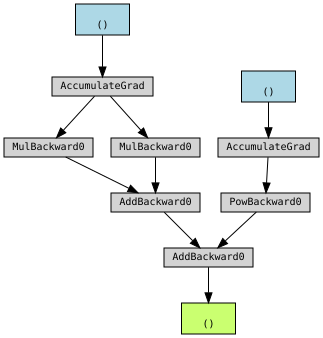

In [ ]:
make_dot(f)

Let's now redefine the function to use `torch.sin`:

In [ ]:
#Defino x0 y x1 como tensores que REQUIEREN EL CALCULO DE GRADIENTE
x0 = torch.tensor(1., requires_grad=True)
x1 = torch.tensor(2., requires_grad=True)

#Ahora si USO TORCH.SIN , la funcion que si entiende PyTorch
f = 2*x0 + x0*torch.sin(x1) + x1**3
print(f)

f.backward()
print(x0.grad, x1.grad)  #Imprimo el atributo .grad de cada tensor

tensor(10.9093, grad_fn=<AddBackward0>)
tensor(2.9093) tensor(11.5839)


Now the gradients are the correct ones!!!

Sadly, torch doesn't warn us when we use non-torch functions for which autodiff is not supported, so it is crucial to stay alert when writing your code, otherwise any downstream result will be egregiously wrong!

> ### ⚠️ REGLA DE ORO EN PYTORCH: Funciones Nativas vs. Otras Librerías
>
> **Nunca uses funciones matemáticas de Python estándar (`math.*`) ni de NumPy (`np.*`) en expresiones con tensores que requieran gradiente.**
>
> #### 🛑 El peligro del "Error Silencioso"
> PyTorch **NO muestra ningún aviso ni error** cuando utilizas funciones de otras librerías[cite: 14]. En su lugar:
> 1. Extrae el valor numérico bruto del tensor[cite: 12, 13].
> 2. **Rompe el Grafo Computacional** (*Wengert List*), perdiendo la traza de la variable[cite: 12, 13, 14].
> 3. Trata ese término como una constante fija, devolviendo un gradiente totalmente incorrecto durante el `.backward()`[cite: 12, 13, 14].
>
> ---
>
> #### 🔍 Comparativa de comportamiento
>
> | Operación utilizada | Registro en el Grafo | Resultado del Gradiente (`x1.grad`) |
> | :--- | :--- | :--- |
> | **`math.sin(x1)`**[cite: 12, 13] | Rompe la cadena. No añade nodo de derivada[cite: 12, 13, 14]. | ❌ **Incorrecto** (`12.0`)[cite: 12, 13] |
> | **`torch.sin(x1)`**[cite: 14] | Añade el nodo **`SinBackward`** al grafo[cite: 14]. | ✅ **Exacto** (`11.5839`)[cite: 14] |
>
> **En resumen:** Para garantizar que la diferenciación automática funcione correctamente, **todas las operaciones matemáticas** sobre tensores con `requires_grad=True` deben ser funciones nativas del módulo `torch` (ej. `torch.sin`, `torch.cos`, `torch.exp`, `torch.log`)[cite: 14].

Let's confirm all of this by looking at the computational graph: can you spot the autodiff-supported version of `sin` (`SinBackward`), now?

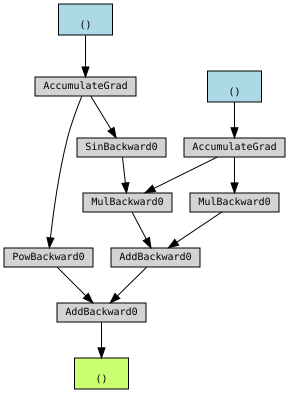

In [ ]:
make_dot(f)

Let's also notice two important peculiarities of automatic differentiation.

Let's propagate the gradients again, without redefining the function:

In [ ]:

print(f)
f.backward()   #PYTORCH alerta de que ya hicimos BACKPROPAGATION 1 VEZ con esos valores
print(x0.grad, x1.grad)

tensor(10.9093, grad_fn=<AddBackward0>)


RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.

Torch correctly warns us that we had already propagated gradients through $f(x_0, x_1)$ once.

Let's then recreate the function, and run backwards again:

In [ ]:
f= 2*x0 + x0*torch.sin(x1) + x1**3
print(f)

f.backward()
print(x0.grad, x1.grad)

tensor(10.9093, grad_fn=<AddBackward0>)
tensor(5.8186) tensor(23.1677)


# ⚠️ La Acumulación de Gradientes en PyTorch

## 1. El Grafo se Destruye tras `.backward()`
Al ejecutar `f.backward()`, PyTorch calcula las derivadas y **libera la memoria del grafo computacional**. Si intentas llamar a `.backward()` una segunda vez sobre la misma variable sin volver a definirla, obtendrás un `RuntimeError`[cite: 12].

## 2. Los Gradientes NO se Sobreescriben, se Suman
Por defecto, cada llamada a `.backward()` **añade (+=)** el nuevo gradiente al valor existente en la propiedad `.grad` del tensor[cite: 12]:

$$\text{Nuevo } x.grad = \text{Anterior } x.grad + \text{Gradiente actual}$$

Si ejecutas la celda $3$ veces seguidas sin limpiar los gradientes, obtendrás exactamente $3 \times \text{gradiente}$[cite: 12].

---

## 🛠️ ¿Cómo solucionarlo?

### Opción A: Reiniciar los gradientes a cero manualmente
Antes de hacer una nueva pasada hacia atrás, limpia las propiedades `.grad` con el método `.zero_()`[cite: 12]:

```python
# Reiniciar gradientes a 0
x0.grad.zero_()
x1.grad.zero_()

# Ahora el cálculo dará el valor exacto correcto
f.backward()

What is happening???

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.

The gradients are associated to the tensors $x0$ and $x1$, and are therefore not reset. When we redefine the function, we create a new computational graph (and can therefore call `.backward()` on it), but we haven't reset the gradients of the input tensors, so torch will just sum the new gradients to the old ones. You can cross check that the new gradients are a multiplier of the original ones.

If we want the proper derivatives without accumulation, we need to recreate the input tensors.

Incidentally, this automatic accumulation of gradients is designed on purpose, in `torch`, in order to make backpropagation in neural networks (where with batch or minibatch gradient descent the gradients are accumulated before each step, as we will see tomorrow) very efficiently handy.

In [ ]:
#Volvemos a definir los tensores para limpiar el GRADIENTE calculado anteriormente
x0 = torch.tensor(1., requires_grad=True)
x1 = torch.tensor(2., requires_grad=True)

f= 2*x0 + x0*torch.sin(x1) + x1**3
print(f)
f.backward()
print(x0.grad, x1.grad)

#Ahora si calcula bien, con grado limpio
#Y sin hacer backpropagation sobre los mismos tensores

tensor(10.9093, grad_fn=<AddBackward0>)
tensor(2.9093) tensor(11.5839)


# The end of part 1